In [3]:
import pandas

Part 2

In [12]:
df = pandas.read_csv('../../course_assignments/homework7/state_data.csv', sep = ',')

In [14]:
df.shape # 52 rows, 4 columns

(52, 4)

In [16]:
print(df.head(5))
print(df.tail(5))
# column 0 is 2-letter stare name code, column 1 is latitiude, column 2 is longitude, column 3 is full name
# first state is Alaska, last state is Wyoming, there are 52 entries, the extra 2 entries are DC and Putero Rico

  state   latitude   longitude        name
0    AK  63.588753 -154.493062      Alaska
1    AL  32.318231  -86.902298     Alabama
2    AR  35.201050  -91.831833    Arkansas
3    AZ  34.048928 -111.093731     Arizona
4    CA  36.778261 -119.417932  California
   state   latitude   longitude           name
47    VT  44.558803  -72.577841        Vermont
48    WA  47.751074 -120.740139     Washington
49    WI  43.784440  -88.787868      Wisconsin
50    WV  38.597626  -80.454903  West Virginia
51    WY  43.075968 -107.290284        Wyoming


In [19]:
print(df['latitude'].median())
print(df['longitude'].median())
# median longitude is -89.093198, median latitude is 39.4355155

39.4355155
-89.093198


In [21]:
df['lat-diff'] = abs(df['latitude'] - df['latitude'].median())
df['long-diff'] = abs(df['longitude'] - df['longitude'].median())

In [22]:
df.shape # 52 rows, 6 columns

(52, 6)

In [33]:
print(f'Minimum difference from median latitude is {df.loc[df['lat-diff'].idxmin(), 'name']} with a distance of {df['lat-diff'].min():.2f}')
print(f'Minimum difference from median longitude is {df.loc[df['long-diff'].idxmin(), 'name']} with a distance of {df['long-diff'].min():.2f}')
print(f'Maximum difference from median latitude is {df.loc[df['lat-diff'].idxmax(), 'name']} with a distance of {df['lat-diff'].max():.2f}')
print(f'Maximum difference from median longitude is {df.loc[df['long-diff'].idxmax(), 'name']} with a distance of {df['long-diff'].max():.2f}')

Minimum difference from median latitude is Colorado with a distance of 0.11
Minimum difference from median longitude is Illinois with a distance of 0.31
Maximum difference from median latitude is Alaska with a distance of 24.15
Maximum difference from median longitude is Hawaii with a distance of 66.57


In [32]:
df['lat-diff'].argmax()

np.int64(0)

In [36]:
df['notnull'] = df['name'].notnull()
# https://pandas.pydata.org/docs/reference/general_functions.html#top-level-missing-data
# used to return a true value table of not null data, useful to detect bad data

Part 3

In [48]:
import seaborn as sns
import matplotlib.pyplot as plt

In [49]:
dj = sns.load_dataset('tips')

In [50]:
dj.dropna(axis=1)

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [52]:
dj.shape # 244 rows, 7 columns

(244, 7)

In [54]:
print(dj.head(5))
print(dj.tail(5))
# total_bill, tip, time, day: literal meaning. Sex, size, smoker: the number and sex of consumers, and whether the consumer smokes

   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4
     total_bill   tip     sex smoker   day    time  size
239       29.03  5.92    Male     No   Sat  Dinner     3
240       27.18  2.00  Female    Yes   Sat  Dinner     2
241       22.67  2.00    Male    Yes   Sat  Dinner     2
242       17.82  1.75    Male     No   Sat  Dinner     2
243       18.78  3.00  Female     No  Thur  Dinner     2


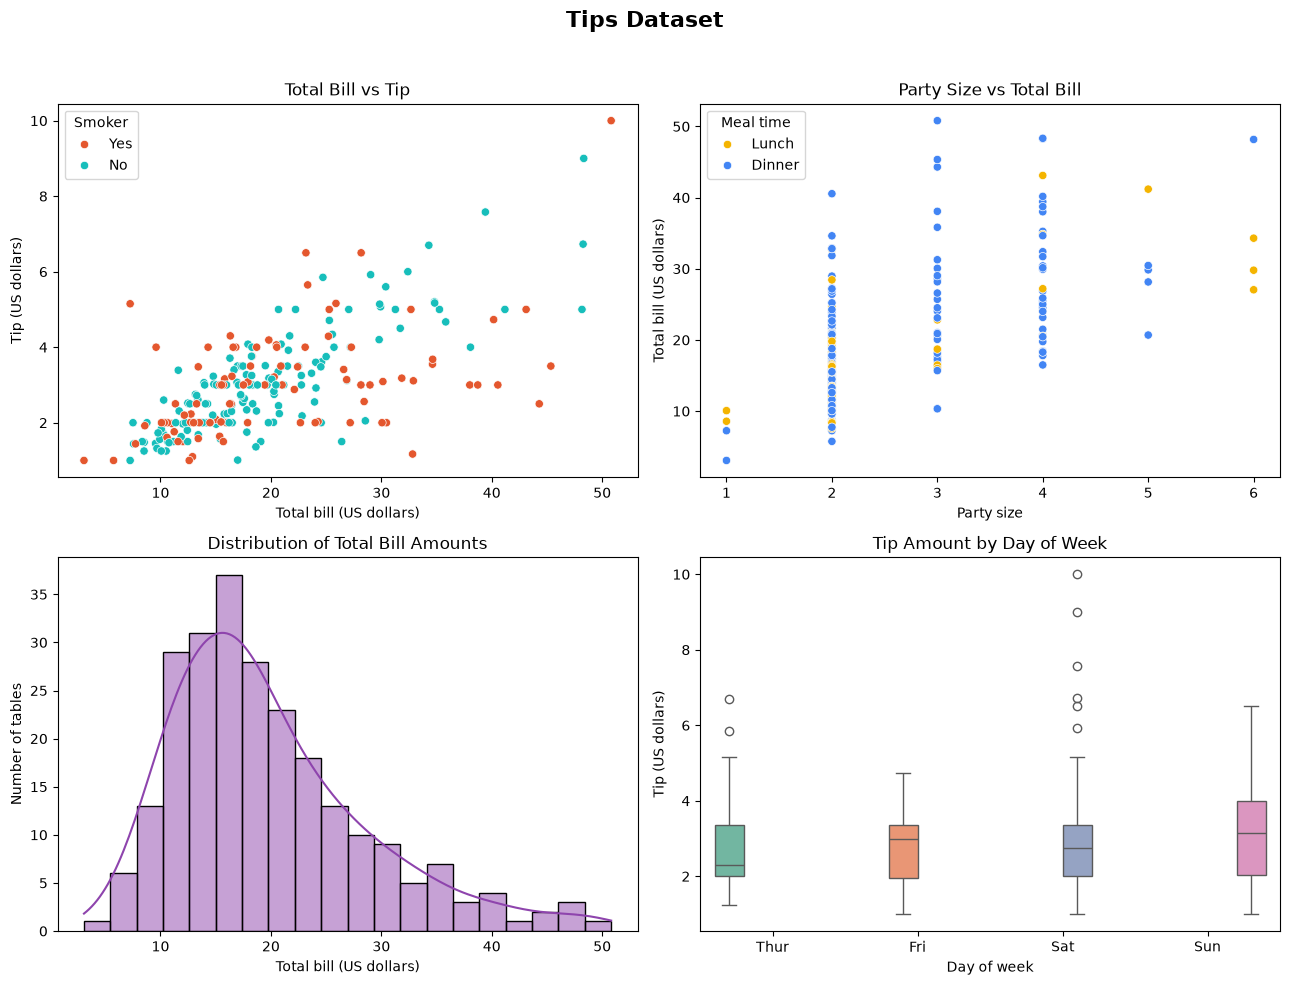

In [59]:
import matplotlib.pyplot as plt
import seaborn as sns
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
fig.suptitle("Tips Dataset", fontsize=16, fontweight="bold")
sns.scatterplot(
    data=dj,
    x="total_bill",
    y="tip",
    hue="smoker",
    palette={"Yes": "#E4572E", "No": "#17BEBB"},
    ax=axes[0, 0]
)
axes[0, 0].set_title("Total Bill vs Tip")
axes[0, 0].set_xlabel("Total bill (US dollars)")
axes[0, 0].set_ylabel("Tip (US dollars)")
axes[0, 0].legend(title="Smoker")
sns.scatterplot(
    data=dj,
    x="size",
    y="total_bill",
    hue="time",
    palette={"Lunch": "#F4B400", "Dinner": "#4285F4"},
    ax=axes[0, 1]
)
axes[0, 1].set_title("Party Size vs Total Bill")
axes[0, 1].set_xlabel("Party size")
axes[0, 1].set_ylabel("Total bill (US dollars)")
axes[0, 1].legend(title="Meal time")
sns.histplot(
    data=dj,
    x="total_bill",
    bins=20,
    kde=True,
    color="#8E44AD",
    ax=axes[1, 0]
)
axes[1, 0].set_title("Distribution of Total Bill Amounts")
axes[1, 0].set_xlabel("Total bill (US dollars)")
axes[1, 0].set_ylabel("Number of tables")
sns.boxplot(
    data=dj,
    x="day",
    y="tip",
    hue="day",
    palette="Set2",
    legend=False,
    ax=axes[1, 1]
)
axes[1, 1].set_title("Tip Amount by Day of Week")
axes[1, 1].set_xlabel("Day of week")
axes[1, 1].set_ylabel("Tip (US dollars)")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [60]:
# top-left: total bill and tips. Tips go up with total bill
# top right: party size and total bill. Bill goes up with party size
# bottom left: total bill amount and number of tables. most table spent about 16 dollars. 
# bottom right: tips on week. on saturday we have the most outliers. 